# PRODUCT ANALYSIS

In [1]:
import pandas as pd

In [8]:
df = pd.read_csv('../data/processed/events_clean.csv')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2755641 entries, 0 to 2755640
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   visitorid      int64  
 1   event          str    
 2   itemid         int64  
 3   transactionid  float64
 4   datetime       str    
dtypes: float64(1), int64(2), str(2)
memory usage: 105.1 MB


In [10]:
df['datetime'] = pd.to_datetime(df['datetime'])

In [11]:
df.shape

(2755641, 5)

In [12]:
df.head()

,visitorid,event,itemid,transactionid,datetime
0,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,951259,view,367447,NaN,2015-06-02 05:02:17.106


## Активность товаров

### Количество уникальных itemid для view, addtocart, transaction

In [22]:
df.groupby('event')['itemid'].nunique()

event
addtocart       23903
transaction     12025
view           234838
Name: itemid, dtype: int64

### Количество уникальных товаров во всей таблице

In [23]:
df['itemid'].nunique()

235061

In [34]:
(df.groupby('event')['itemid'].nunique()/df['itemid'].nunique()).mul(100).round(2)

event
addtocart      10.17
transaction     5.12
view           99.91
Name: itemid, dtype: float64

## Лидеры

### Топ 10 товаров по числу уникальных пользователей, которые их просматривали

In [41]:
top10_vis_view = df[df['event'] == 'view'].groupby('itemid')['visitorid'].nunique().sort_values(ascending=False).head(10)
top10_vis_view

itemid
187946    2911
5411      2078
370653    1577
461686    1379
96924     1359
219512    1358
298009    1342
335975    1154
384302    1143
151444    1103
Name: visitorid, dtype: int64

### Топ 10 товаров по числу уникальных покупателей

In [42]:
top10_vis_trans = df[df['event'] == 'transaction'].groupby('itemid')['visitorid'].nunique().sort_values(ascending=False).head(10)
top10_vis_trans

itemid
461686    129
213834     80
7943       46
119736     42
445351     42
48030      38
312728     37
420960     36
17478      35
416017     32
Name: visitorid, dtype: int64

In [44]:
top10_vis_view.index.intersection(top10_vis_trans.index)

Index([461686], dtype='int64', name='itemid')

In [52]:
import matplotlib.pyplot as plt

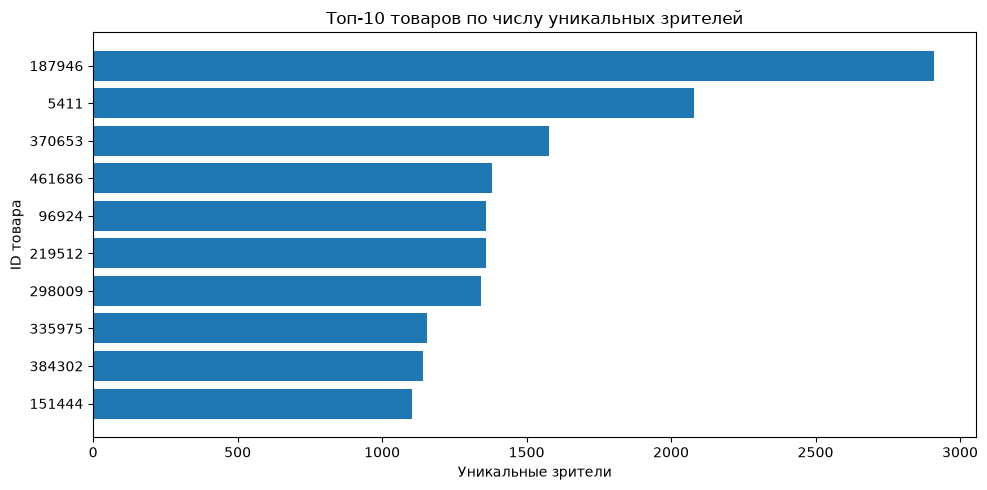

In [54]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10_vis_view.index.astype(str), top10_vis_view.values)
ax.invert_yaxis()
ax.set_title('Топ-10 товаров по числу уникальных зрителей')
ax.set_xlabel('Уникальные зрители')
ax.set_ylabel('ID товара')
plt.tight_layout()
plt.show()

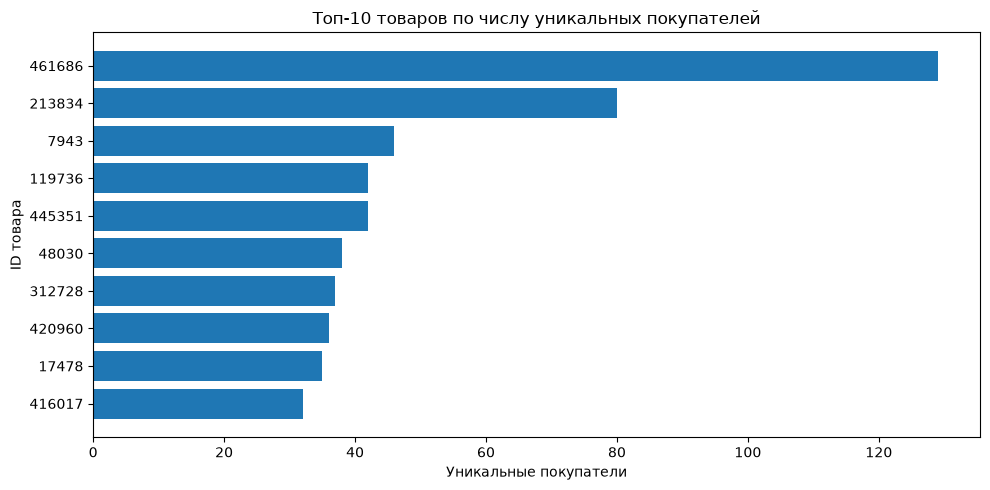

In [55]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10_vis_trans.index.astype(str), top10_vis_trans.values)
ax.invert_yaxis()
ax.set_title('Топ-10 товаров по числу уникальных покупателей')
ax.set_xlabel('Уникальные покупатели')
ax.set_ylabel('ID товара')
plt.tight_layout()
plt.show()

## Концентрация

### Концентрация просмотров

In [64]:
count_view_item = df[df['event'] == 'view'].groupby('itemid').agg(count = ('event', 'count'))
count_view_item

,count
itemid,
3,2
4,3
6,29
9,2
15,18
...,...
466861,89
466862,4
466863,1


In [66]:
count_view_item['count'].sum()

np.int64(2664218)

#### Какая доля всех просмотров приходится на топ-1% товаров

In [75]:
top_n = int(df["itemid"].nunique() * 0.01)

In [76]:
top_items = count_view_item.sort_values("count", ascending=False).head(top_n)

In [74]:
top_view_share_pct = (
    top_items["count"].sum()
    / count_view_item["count"].sum()
    * 100
)
round(top_view_share_pct, 2)

np.float64(22.71)

#### "Длинный хвост"

In [90]:
one_view_items =  count_view_item[count_view_item['count'] == 1]
len(one_view_items)

73799

In [91]:
round(len(one_view_items) / len(count_view_item) * 100, 2)

31.43

### Концентрация покупок

#### Всего событий transaction

In [92]:
df[df['event'] == 'transaction']

,visitorid,event,itemid,transactionid,datetime
130,599528,transaction,356475,4000.0,2015-06-02 05:17:56.276
304,121688,transaction,15335,11117.0,2015-06-01 21:18:20.981
418,552148,transaction,81345,5444.0,2015-06-01 21:25:15.008
814,102019,transaction,150318,13556.0,2015-06-01 16:38:56.375
843,189384,transaction,310791,7244.0,2015-06-01 16:01:58.180
...,...,...,...,...,...
2754835,1050575,transaction,31640,8354.0,2015-07-31 21:12:56.570
2754890,861299,transaction,456602,3643.0,2015-07-31 21:57:58.779
2755048,855941,transaction,235771,4385.0,2015-07-31 15:48:50.123
2755143,548772,transaction,29167,13872.0,2015-07-31 15:12:40.300


In [103]:
count_trans_item = df[df['event'] == 'transaction'].groupby('itemid').size()
count_trans_item

itemid
15        1
19        1
25        2
42        1
147       4
         ..
466526    1
466603    1
466614    2
466710    1
466861    1
Length: 12025, dtype: int64

In [104]:
top_n = int(df["itemid"].nunique() * 0.01)

In [106]:
top_item_trans = count_trans_item.sort_values(ascending=False).head(top_n)
top_item_trans

itemid
461686    133
119736     97
213834     92
312728     46
7943       46
         ... 
196923      2
32888       2
340800      2
445860      2
197422      2
Length: 2350, dtype: int64

In [110]:
top_trans_share_pct = round(top_item_trans.sum() / count_trans_item.sum() * 100, 2)
top_trans_share_pct

np.float64(48.19)

## Категории

In [111]:
category_history = pd.read_csv("../data/processed/item_category_history_clean.csv")

In [112]:
category_history.info()

<class 'pandas.DataFrame'>
RangeIndex: 788214 entries, 0 to 788213
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   itemid         788214 non-null  int64
 1   categoryid     788214 non-null  int64
 2   datetime_item  788214 non-null  str  
dtypes: int64(2), str(1)
memory usage: 18.0 MB


In [113]:
category_history.head()

,itemid,categoryid,datetime_item
0,460429,1338,2015-06-28 03:00:00
1,281245,1277,2015-05-24 03:00:00
2,35575,1059,2015-06-28 03:00:00
3,8313,1147,2015-07-19 03:00:00
4,55102,47,2015-07-26 03:00:00


In [114]:
category_history["datetime_item"] = pd.to_datetime(category_history["datetime_item"])

In [115]:
category_history.dtypes

itemid                    int64
categoryid                int64
datetime_item    datetime64[us]
dtype: object

In [116]:
category_history.duplicated(subset=["itemid", "datetime_item"]).sum()

np.int64(0)

In [117]:
events_sorted = df[["itemid", "event", "datetime"]].sort_values("datetime")
events_sorted

,itemid,event,datetime
1462721,297662,addtocart,2015-05-03 03:00:04.384
1464553,60987,view,2015-05-03 03:00:11.289
1462747,252860,view,2015-05-03 03:00:13.048
1465034,33661,view,2015-05-03 03:00:24.154
1462702,297662,view,2015-05-03 03:00:26.228
...,...,...,...
1460912,301436,view,2015-09-18 02:59:24.029
1456292,310922,view,2015-09-18 02:59:25.499
1456532,47467,view,2015-09-18 02:59:34.109
1453871,345308,view,2015-09-18 02:59:41.778


In [118]:
history_sorted = category_history.sort_values("datetime_item")
history_sorted.head()

,itemid,categoryid,datetime_item
638223,75757,926,2015-05-10 03:00:00
393065,103747,1455,2015-05-10 03:00:00
547041,51970,686,2015-05-10 03:00:00
393060,274307,1553,2015-05-10 03:00:00
195979,84814,568,2015-05-10 03:00:00


In [119]:
events_with_category = pd.merge_asof(
    events_sorted,
    history_sorted,
    left_on="datetime",
    right_on="datetime_item",
    by="itemid",
    direction="backward",
)

events_with_category.shape

(2755641, 5)

In [121]:
round(events_with_category["categoryid"].notna().mean() * 100, 2)

np.float64(76.16)

### Категории с наибольшим числом просмотров

In [122]:
views_with_category = events_with_category[
    (events_with_category["event"] == "view")
    & events_with_category["categoryid"].notna()
]

views_with_category.shape

(2023488, 5)

In [123]:
views_by_category = (views_with_category.groupby("categoryid").size().sort_values(ascending=False))
views_by_category

categoryid
1051.0    62365
1483.0    52646
959.0     43450
342.0     39221
1613.0    30530
          ...  
321.0         1
674.0         1
482.0         1
1138.0        1
357.0         1
Length: 1139, dtype: int64

### График топ-10 категорий по числу просмотров

In [131]:
top10_categories_view = views_by_category.head(10)

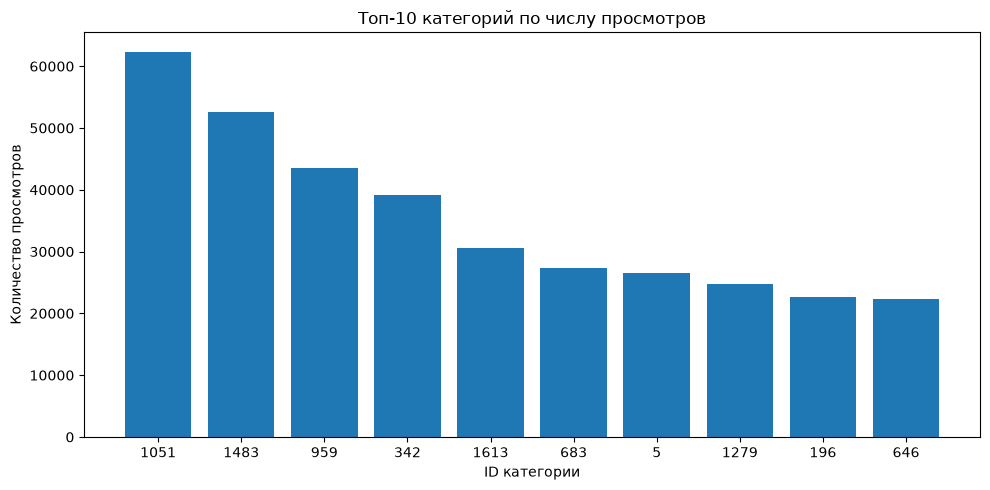

In [134]:
fig, ax = plt.subplots(figsize = (10, 5) )
ax.bar(top10_categories_view.index.astype(int).astype(str), top10_categories_view.values)
ax.set_title("Топ-10 категорий по числу просмотров")
ax.set_xlabel("ID категории")
ax.set_ylabel("Количество просмотров")
plt.tight_layout()
plt.show()

### График топ-10 категорий по числу событий transaction

In [135]:
transactions_by_category = (
    events_with_category[
        (events_with_category["event"] == "transaction")
        & events_with_category["categoryid"].notna()
    ]
    .groupby("categoryid")
    .size()
    .sort_values(ascending=False)
)

transactions_by_category.head(10)

categoryid
959.0     464
1051.0    421
1483.0    369
196.0     260
1542.0    248
342.0     235
1163.0    229
1037.0    222
686.0     210
618.0     200
dtype: int64

In [136]:
top10_categories_trans = transactions_by_category.head(10)

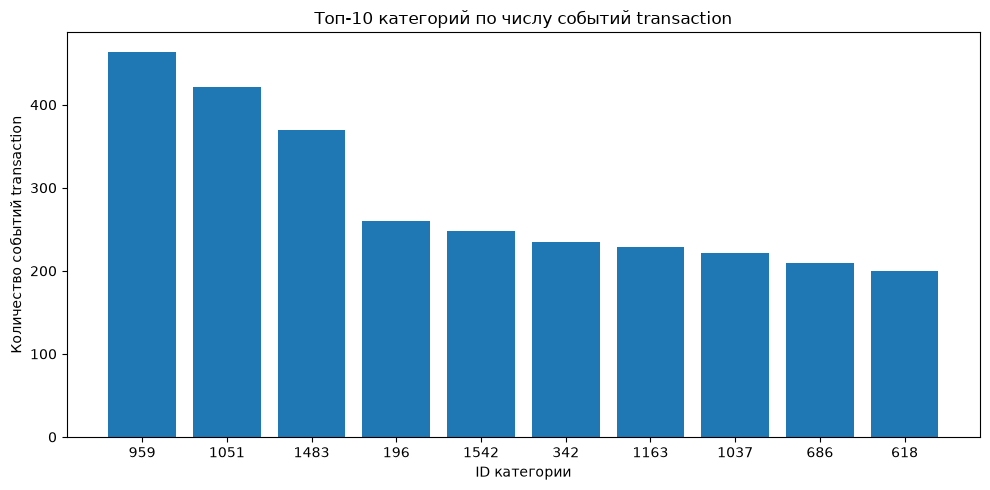

In [138]:
fig, ax = plt.subplots(figsize = (10, 5) )
ax.bar(top10_categories_trans.index.astype(int).astype(str), top10_categories_trans.values)
ax.set_title("Топ-10 категорий по числу событий transaction")
ax.set_xlabel("ID категории")
ax.set_ylabel("Количество событий transaction")
plt.tight_layout()
plt.show()

## Выводы

- В событиях встречается 235 061 уникальных товаров. Просмотры есть у 234 838 товаров, события `transaction` - у 12 025. Это охват товаров по типам событий.
- Активность распределена неравномерно: на топ-1% всех наблюдаемых товаров (2 350 товаров) приходится 22,71% просмотров и 48,19% событий `transaction`. Топ для каждого типа событий рассчитан отдельно.
- 73 799 товаров получили ровно один просмотр - это 31,43% товаров, у которых был хотя бы один просмотр.
- Категорию на момент события удалось определить для 76,16% событий. События без известной категории не входят в рейтинги категорий.
- По числу просмотров лидирует категория с ID 1051 (62 365 событий `view`), по числу событий `transaction` - категория с ID 959 (464 события). Названия категорий неизвестны. События `transaction` не равны уникальным заказам.